# Bloque 4. Construcción de la serie temporal

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alvaroparedesl/geomatica-aplicada/blob/main/talleres/fair-series-temporales/04_series_temporales.ipynb) [![Licencia: GPL-3.0](https://img.shields.io/badge/licencia-GPL--3.0-blue.svg)](https://github.com/alvaroparedesl/geomatica-aplicada/blob/main/LICENSE) [![Python 3.13](https://img.shields.io/badge/python-3.13-blue.svg)](https://colab.research.google.com/)

Taller *Datos FAIR, series temporales satelitales y detección de anomalías con Python*. Día 1, tarde (unos 90 minutos).

Hasta ahora trabajaste con **una** imagen. Una serie temporal es lo mismo repetido en el tiempo: el valor de una variable en un punto, fecha tras fecha. En este bloque construyes esa serie desde cero con Sentinel-2, la guardas con sus metadatos (el momento FAIR del día) y la miras.

**Qué vas a hacer**

| Parte | Tema | Minutos |
|---|---|---|
| 1 | De una imagen a una serie: revisita y nubes | 15 |
| 2 | Los puntos de muestreo (CSV) y su mapa | 15 |
| 3 | Búsqueda y carga de ventanas pequeñas (patrón nativo) | 20 |
| 4 | Máscara SCL, reflectancia e índices, paso a paso | 10 |
| 5 | La serie de todos los puntos | 5 |
| 6 | Filtro de escena frente a máscara SCL: lo medimos | 10 |
| 7 | Guardar en parquet con metadatos (FAIR) | 5 |
| 8 | La serie de 12 meses de respaldo y su gráfico | 10 |

Seguimos el **patrón nativo** del curso: la búsqueda (`pystac_client`) y la carga (`odc.stac.load`) las escribes tú. Los helpers de `utils/` solo **preparan** sus argumentos y ordenan los datos antes y después.

## Preparar el entorno

La celda `Preparar entorno` clona el repositorio del curso (para usar `utils/`). La siguiente instala los paquetes de STAC que Colab no trae, solo si faltan.

In [1]:
# @title Preparar entorno (ejecutar primero)
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: clonar el repositorio (y actualizarlo si ya estaba)
    RAIZ = Path("/content/geomatica-aplicada")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/alvaroparedesl/geomatica-aplicada", str(RAIZ)], check=True)
    else:  # una sesión anterior ya lo clonó: traer lo nuevo para no usar código viejo
        subprocess.run(["git", "-C", str(RAIZ), "pull", "-q", "--ff-only"], check=False)
else:  # Local: subir desde la carpeta actual hasta encontrar utils/
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir())
sys.path.insert(0, str(RAIZ))
DATOS = RAIZ / "talleres" / "fair-series-temporales" / "datos"  # carpeta con los archivos de datos del taller

In [2]:
# @title Instalar los paquetes de este bloque (solo si faltan)
import importlib.util

# Paquete de requirements.txt -> nombre con el que se importa
NECESARIOS = {"pystac-client": "pystac_client", "planetary-computer": "planetary_computer",
              "odc-stac": "odc.stac", "rioxarray": "rioxarray"}
requisitos = [linea.strip() for linea in (RAIZ / "talleres/fair-series-temporales/requirements.txt").read_text().splitlines()
              if linea.strip() and not linea.startswith("#")]
requisitos = [r for r in requisitos if r.split()[0] in NECESARIOS]

if any(importlib.util.find_spec(modulo) is None for modulo in NECESARIOS.values()):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requisitos], check=True)
    print("Instalado:", ", ".join(requisitos))
else:
    print("Ya está todo instalado:", ", ".join(NECESARIOS))

Instalado: pystac-client, planetary-computer, odc-stac, rioxarray


In [3]:
# @title Importar bibliotecas
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import odc.stac
import pandas as pd
import planetary_computer
import plotly.express as px
import pyarrow.parquet as pq
import pystac_client
import xarray as xr
from matplotlib.colors import ListedColormap
from shapely.geometry import box, shape

# Funciones de apoyo del curso (carpeta utils/)
from utils.series import (agregar_nubes_escena, bbox_punto, bbox_puntos, cargar_puntos_csv, cargar_ventanas,
                          construir_series, crs_utm, guardar_series, resumen_validez)
from utils.stac import parametros_busqueda, parametros_carga, preparar_items, resumir_imagenes
from utils.viz import mapa_puntos

warnings.filterwarnings("ignore", category=UserWarning)  # avisos de GDAL por escenas sin georreferencia

# Una paleta distinguible con daltonismo (Okabe-Ito), una por punto
PALETA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]

## Dos funciones para pasar de DN a reflectancia

En el bloque 3 convertiste a mano una imagen: `reflectancia = DN * 0,0001 + offset`, con el offset según el baseline de la imagen. Aquí hay muchas fechas, cada una con su baseline, así que dejamos esos pasos en dos funciones **escritas aquí**, para que puedas leerlas (y cambiarlas). Sirven solo para Sentinel-2 de Planetary Computer.

In [4]:
def agregar_offset(datos, items):
    # El offset depende del baseline de procesamiento de cada imagen, que está en sus metadatos:
    # baseline 04.00 o posterior -> -0.1 (a los DN se les sumaron 1000); anterior -> 0
    offset_por_fecha = {}
    for item in items:
        fecha = np.datetime64(item.datetime.replace(tzinfo=None), "ns")
        baseline = float(item.properties["s2:processing_baseline"])  # "05.11" -> 5.11
        offset_por_fecha[fecha] = -0.1 if baseline >= 4.0 else 0.0
    # La fecha de cada capa de `datos` es la de la primera imagen de su grupo: ahí buscamos su offset
    offsets = [offset_por_fecha[fecha] for fecha in datos["time"].values.astype("datetime64[ns]")]
    return datos.assign_coords(offset_reflectancia=("time", offsets))


def reflectancia_sentinel2(datos):
    # Convierte antes de combinar fechas (por ejemplo antes de .median("time")): después ya no hay un offset por fecha
    # reflectancia = DN * 0.0001 + offset de cada fecha (el DN 0 significa "sin dato")
    refl = datos.where(datos != 0) * 0.0001 + datos["offset_reflectancia"]
    # Una reflectancia válida está entre 0 y 1: lo demás pasa a NaN
    refl = refl.where((refl >= 0) & (refl <= 1))
    return refl.drop_vars("offset_reflectancia")

## 1. De una imagen a una serie temporal

Tres ideas explican casi todo lo que viene.

**Revisita.** Sentinel-2 vuelve a pasar por el mismo lugar cada pocos días (con tres satélites en órbita y escenas que se traslapan, en Concepción hay una toma cada dos o tres días). Cada toma es una **fecha** de la serie. Las fechas no son regulares ni diarias, y eso importa al calcular promedios móviles (bloque 5).

**Nubes.** Una serie con nubes mezcladas es una serie equivocada: una nube es blanca y hace que el agua parezca otra cosa. Hay dos formas de tratarlas, y no hacen lo mismo:

| | Filtro de escena (`eo:cloud_cover`) | Máscara de píxel (banda SCL) |
|---|---|---|
| Dónde actúa | En la búsqueda STAC, antes de cargar | Después de cargar, píxel por píxel |
| Qué descarta | Fechas completas | Píxeles con nube, sombra, cirrus, saturados o sin dato |
| Qué sabe de tu punto | Nada: es el porcentaje de **toda la escena** (unos 100 x 100 km) | Todo: mira justo tus píxeles |
| Costo | Ahorra datos descargados | Hay que cargar la fecha para poder juzgarla |

Más abajo medimos cuánto cambia cada una en nuestros puntos.

**Puntos y ventanas.** Cargar el área completa que encierra todos los puntos es mucho más pesado que cargar una **ventana pequeña** (unos 300 x 300 m) alrededor de cada uno. Para series en puntos, la ventana alcanza: de cada fecha resumimos sus píxeles con la mediana, que resiste algún píxel raro.

## 2. Los puntos de muestreo

Los puntos están en un archivo CSV con las columnas `id, nombre, lat, lon, tipo`. `cargar_puntos_csv` lo lee y valida (columnas, `id` únicos, rangos de latitud y longitud). Un nombre simple busca el archivo en la carpeta `datos/` del taller.

In [5]:
puntos = cargar_puntos_csv("PuntosHumboldt02.csv")
puntos

,id,nombre,lat,lon,tipo
0,humedal_loschoros,Humedal Quebrada Los Choros,-29.294899,-71.329536,humedal
1,callejon,Callejón Isla Choros y Damas,-29.242793,-71.532855,insular
2,playa_loschoros,Playa Los Choros,-29.299750,-71.386306,Playa
3,elapolillado,Playa El Apolillado,-29.174904,-71.488811,Bahia
4,carrizalillo,Playa Carrizalillo,-29.099813,-71.472609,Bahia
5,elapolillado02,El Apolillado 02,-29.173658,-71.507353,bahia


Se dibuja un mapa con la ubicación de los seis puntos de muestreo. Alrededor de cada punto se muestra un círculo de 150 m de radio, que representa el área donde se promediaron los píxeles de Sentinel-2 y Landsat para construir las series. Esto permite revisar si cada área cae completamente sobre agua o si incluye tierra, playa o vegetación, algo clave para interpretar los resultados. Por ejemplo, explica los valores atípicos del humedal y de Playa El Apolillado.

In [6]:
mapa_puntos(puntos, radio_m=150)

> **Opcional: QGIS.** QGIS es solo un apoyo; todo el análisis se hace aquí, en Colab. Si lo tienes instalado puedes:
>
> 1. Abrir `puntos_concepcion.geojson` (carpeta `talleres/fair-series-temporales/datos/` del repositorio) con *Capa > Añadir capa > Añadir capa vectorial*.
> 2. Editar o agregar puntos: activa la edición de la capa, usa *Añadir punto* y completa `id` (sin espacios ni repetidos), `nombre`, `tipo` y las coordenadas `lat` y `lon` en grados decimales.
> 3. Exportar a CSV: clic derecho en la capa, *Exportar > Guardar objetos como...*, formato CSV, codificación UTF-8 y, en las opciones de la capa, `GEOMETRY = AS_XY` (así se agregan las columnas de coordenadas; renómbralas a `lon` y `lat` si hace falta). El archivo debe tener exactamente las columnas `id, nombre, lat, lon, tipo`.
> 4. Subir el CSV a Colab (panel de archivos de la izquierda) y leerlo con `cargar_puntos_csv("/content/mis_puntos.csv")`.
>
> Con QGIS también puedes mirar una o dos imágenes Sentinel-2 (por ejemplo con el complemento de STAC), pero el cubo de datos lo seguimos construyendo en Colab.


Se buscan todas las imágenes Sentinel-2 disponibles para el área de estudio entre el 1 de enero de 2020 y el 1 de octubre de 2026. Primero, bbox_puntos calcula un solo rectángulo que contiene las ventanas de unos 300 × 300 m (150 m de radio) alrededor de los seis puntos, y se imprimen sus coordenadas. Con ese rectángulo se hace una única búsqueda en el catálogo STAC de Microsoft Planetary Computer. Después, cada punto se queda solo con las imágenes que lo cubren. Se aceptan escenas con hasta 100 % de nubes a propósito, para poder comparar más adelante distintos filtros de nubosidad con una sola carga. Al final, preparar_items elimina versiones duplicadas de una misma escena y se imprime el número de imágenes encontradas.

In [8]:
FECHAS = ("2020-01-01", "2026-10-01")
RADIO_M = 150  # ventana de unos 300 x 300 m alrededor de cada punto

bbox = bbox_puntos(puntos, RADIO_M)
print("bbox de la zona (oeste, sur, este, norte):", [round(c, 3) for c in bbox])

# Catálogo STAC de Planetary Computer; `sign_inplace` firma los enlaces de descarga de cada imagen
catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
parametros = parametros_busqueda("sentinel-2", bbox, FECHAS, nubes_max=100, catalogo=catalogo)
busqueda = catalogo.search(**parametros)  # llamada nativa de pystac_client
items = busqueda.item_collection()
items = preparar_items(items)  # sin versiones duplicadas y de un solo catálogo
print(f"{len(items)} imágenes (escenas) entre {FECHAS[0]} y {FECHAS[1]}")

bbox de la zona (oeste, sur, este, norte): [-71.534, -29.301, -71.328, -29.098]
Se encontraron 1026 imágenes (sentinel-2-l2a, planetary) (158 versiones repetidas descartadas).
1026 imágenes (escenas) entre 2020-01-01 y 2026-10-01


Se arma una tabla resumen con los metadatos de cada imagen encontrada (fecha, porcentaje de nubes, tesela y versión de procesamiento) y se muestran las primeras ocho filas. Luego se cuenta cuántas imágenes hay de cada processing baseline y de cada offset. Esto importa porque, desde enero de 2022, ESA procesa Sentinel-2 con la baseline 04.00, que agrega un desplazamiento (offset) de −1000 a los valores de reflectancia. Como la serie va de 2020 a 2026, incluye imágenes de antes y después de ese cambio. Hay que corregir ese offset al convertir a reflectancia; si no, aparecería un salto artificial en la serie a partir de 2022.

In [9]:
tabla_items = resumir_imagenes(items)
print(tabla_items.head(8).to_string())
print("\nBaselines:", tabla_items["baseline"].value_counts().to_dict(), "| offsets:", tabla_items["offset"].value_counts().to_dict())

        fecha    nubes_%                                                      id baseline  offset
0  2020-01-02  83.536118  S2B_MSIL2A_20200102T144719_R139_T19JBH_20201002T220754    02.12     0.0
1  2020-01-04  64.026910  S2A_MSIL2A_20200104T143721_R096_T19JBH_20201002T224452    02.12     0.0
2  2020-01-07   3.317222  S2A_MSIL2A_20200107T144721_R139_T19JBH_20201105T073258    02.12     0.0
3  2020-01-09   0.854408  S2B_MSIL2A_20200109T143719_R096_T19JBH_20201029T180709    02.12     0.0
4  2020-01-12  77.562638  S2B_MSIL2A_20200112T144659_R139_T19JBH_20201002T175750    02.12     0.0
5  2020-01-14  73.744091  S2A_MSIL2A_20200114T143701_R096_T19JBH_20201002T182720    02.12     0.0
6  2020-01-17  65.747337  S2A_MSIL2A_20200117T144701_R139_T19JBH_20201002T194755    02.12     0.0
7  2020-01-19  62.871857  S2B_MSIL2A_20200119T143659_R096_T19JBH_20201002T205450    02.12     0.0

Baselines: {'05.11': 249, '05.10': 242, '02.12': 212, '05.12': 106, '04.00': 103, '03.00': 80, '05.09': 28, '05.13': 

¿Cuántas imágenes nos quedarían con cada límite de nubes de escena? Ese filtro actúa en la búsqueda y es lo más barato, pero recuerda que dice algo de toda la escena, no de tu punto.

In [10]:
nubes = tabla_items["nubes_%"]
print(pd.Series({f"nubes <= {limite} %": int((nubes <= limite).sum()) for limite in (10, 30, 60, 100)}).to_string())

nubes <= 10 %      179
nubes <= 30 %      314
nubes <= 60 %      565
nubes <= 100 %    1026


Se prepara la carga de imágenes para un solo punto, Playa Carrizalillo. Primero se define una ventana de unos 300 × 300 m alrededor del punto y se seleccionan solo las escenas que la cubren. Luego se arma un cubo de datos con cinco bandas de Sentinel-2 a 10 m de resolución: verde (B03), rojo (B04), borde rojo (B05), infrarrojo cercano (B08) y la clasificación de escena (SCL), que identifica nubes, sombras y agua. A cada fecha se le agregan el offset de reflectancia, para corregir el cambio de procesamiento de 2022, y el porcentaje de nubes de la escena. La carga es “perezosa”: todavía no se descargan los píxeles, solo se define la estructura del cubo. Por eso el tamaño que se imprime es una estimación de lo que ocupará cuando se lea.

In [13]:
punto = puntos.loc[puntos["id"] == "carrizalillo"].iloc[0]
bbox_p = bbox_punto(punto["lon"], punto["lat"], RADIO_M)  # ventana de unos 300 x 300 m
# Solo las escenas cuya huella toca la ventana (una escena puede cubrir unos puntos y otros no)
ventana_p = box(*bbox_p)
items_p = [item for item in items if shape(item.geometry).intersects(ventana_p)]
bandas = ["B03", "B04", "B05", "B08", "SCL"]  # verde, rojo, borde rojo, NIR y la banda de clasificación (SCL)
print("Bandas:", bandas)

parametros_ds = parametros_carga("sentinel-2", bandas, resolucion=10, crs=crs_utm(punto["lon"], punto["lat"]),
                                 catalogo=catalogo, bbox=bbox_p, chunks={"x": 512, "y": 512})
datos_p = odc.stac.load(items_p, **parametros_ds)  # llamada nativa de odc.stac (perezosa)
datos_p = agregar_offset(datos_p, items_p)  # offset de reflectancia de cada fecha
datos_p = agregar_nubes_escena(datos_p, items_p)  # % de nubes de la escena de cada fecha
print(f"{len(items_p)} imágenes -> {datos_p.sizes['time']} fechas, ventana de {datos_p.sizes['x']} x {datos_p.sizes['y']} píxeles")
print(f"Tamaño del cubo de este punto: {datos_p.nbytes / 1e6:.1f} MB (todavía sin leer)")
datos_p

Bandas: ['B03', 'B04', 'B05', 'B08', 'SCL']
1018 imágenes -> 989 fechas, ventana de 32 x 32 píxeles
Tamaño del cubo de este punto: 20.3 MB (todavía sin leer)


<xarray.Dataset> Size: 20MB
Dimensions:              (y: 32, x: 32, time: 989)
Coordinates:
  * y                    (y) float64 256B 6.779e+06 6.779e+06 ... 6.778e+06
  * x                    (x) float64 256B 2.592e+05 2.592e+05 ... 2.595e+05
  * time                 (time) datetime64[ns] 8kB 2020-01-02T14:47:19.024000...
    offset_reflectancia  (time) float64 8kB 0.0 0.0 0.0 0.0 ... -0.1 -0.1 -0.1
    nubes_escena         (time) float64 8kB 83.54 64.03 3.317 ... 78.85 16.37
    spatial_ref          int32 4B 32719
Data variables:
    B03                  (time, y, x) float32 4MB dask.array<chunksize=(1, 32, 32), meta=np.ndarray>
    B04                  (time, y, x) float32 4MB dask.array<chunksize=(1, 32, 32), meta=np.ndarray>
    B05                  (time, y, x) float32 4MB dask.array<chunksize=(1, 32, 32), meta=np.ndarray>
    B08                  (time, y, x) float32 4MB dask.array<chunksize=(1, 32, 32), meta=np.ndarray>
    SCL                  (time, y, x) float32 4MB dask.array<chunksize=(1, 32, 32), meta=np.ndarray>

Se estima cuánta memoria ocuparía cargar las imágenes de dos formas distintas. Primero se calcula el tamaño en kilómetros del rectángulo que contiene todos los puntos, convirtiendo grados a metros (en longitud se corrige por la latitud), y a partir de ahí cuántos píxeles de 10 m tendría. Con eso se estima el peso de cargar la caja completa con las cinco bandas y todas las fechas. Después se compara con cargar solo las seis ventanas pequeñas de 300 × 300 m alrededor de cada punto.

In [14]:
lat_media = (bbox[1] + bbox[3]) / 2
ancho_m = (bbox[2] - bbox[0]) * 111_320 * math.cos(math.radians(lat_media))
alto_m = (bbox[3] - bbox[1]) * 111_320
pixeles_caja = (ancho_m / 10) * (alto_m / 10)
gb_caja = pixeles_caja * len(bandas) * datos_p.sizes["time"] * 4 / 1e9
mb_ventanas = len(puntos) * datos_p.nbytes / 1e6
print(f"Caja completa ({ancho_m / 1000:.0f} x {alto_m / 1000:.0f} km): unos {gb_caja:.0f} GB")
print(f"Seis ventanas de 300 x 300 m: unos {mb_ventanas:.0f} MB")

Caja completa (20 x 23 km): unos 89 GB
Seis ventanas de 300 x 300 m: unos 122 MB


Se obtienen dos números que comparan el peso de cargar los datos de dos formas:

Caja completa (20 × 23 km): unos 89 GB. Es lo que ocuparía descargar toda el área de estudio, con las 5 bandas y todas las fechas de 2020 a 2026. Supera con creces la memoria de Colab (unos 12 GB), así que no se podría cargar.
Seis ventanas de 300 × 300 m: unos 122 MB. Es lo que ocupan solo las ventanas pequeñas alrededor de cada punto. Son unas 700 veces menos datos y caben sin problema en memoria.

Se cargan las ventanas de 300 × 300 m de los seis puntos de una sola vez. cargar_ventanas repite para cada punto lo mismo que se hizo antes con Carrizalillo: selecciona las escenas que cubren su ventana, arma el cubo con las cinco bandas y le agrega el offset de reflectancia y el porcentaje de nubes de cada fecha. El resultado es un diccionario, ventanas, con un cubo de datos por punto al que se accede por su id (por ejemplo, ventanas["carrizalillo"]). También se mide e imprime cuántos segundos tardó todo el proceso, para tener una idea del costo de trabajar con la serie completa.

In [15]:
inicio = time.time()
ventanas = cargar_ventanas(items, puntos, radio_m=RADIO_M, catalogo=catalogo)  # dict {id del punto: Dataset}
print(f"Carga total (incluye armar el cubo de cada punto): {time.time() - inicio:.0f} s")

humedal_loschoros: 1024 imágenes, 989 fechas, ventana de 32 x 32 píxeles
callejon: 1023 imágenes, 989 fechas, ventana de 31 x 31 píxeles
playa_loschoros: 1024 imágenes, 989 fechas, ventana de 32 x 32 píxeles
elapolillado: 1021 imágenes, 989 fechas, ventana de 32 x 31 píxeles
carrizalillo: 1018 imágenes, 989 fechas, ventana de 32 x 32 píxeles
elapolillado02: 1021 imágenes, 989 fechas, ventana de 32 x 32 píxeles
Lectura terminada: 120 MB en 2319 s.
Carga total (incluye armar el cubo de cada punto): 2338 s


Se inspecciona el cubo de datos de un punto, Playa Carrizalillo. Primero se imprime su estructura: las dimensiones (tiempo, x, y), las coordenadas y las bandas que contiene. Luego se muestran las primeras cinco fechas con el offset de reflectancia y el porcentaje de nubes de la escena. Como la serie parte en 2020, esas primeras fechas son anteriores al cambio de procesamiento de 2022, así que deberían tener offset 0. Las fechas desde 2022 en adelante tendrán offset −1000.

In [ ]:
ventana = ventanas["carrizalillo"]
print(ventana)
print("\nPrimeras fechas con su offset y las nubes de su escena:")
print(ventana[["offset_reflectancia", "nubes_escena"]].to_dataframe().head(5).to_string())

## 4. Máscara SCL, reflectancia e índices, paso a paso

Antes de usar `construir_series`, hacemos a mano los tres pasos para un punto.

**Paso 1: la máscara SCL.** La banda SCL (*Scene Classification Layer*) asigna a cada píxel una clase (un número entero). La máscara es una pregunta por píxel: ¿su clase está en la lista de clases que descartamos? Con `isin` obtienes un valor `True` donde la respuesta es sí, y con `~` (negación) lo inviertes para quedarte con los píxeles válidos. Estas son las clases que importan (la última columna marca las que descartamos, las mismas que `construir_series` descarta por defecto):

| Código | Clase | ¿Se descarta por defecto? |
|---|---|---|
| 0 | sin datos | sí |
| 1 | saturado | sí |
| 2 | áreas oscuras | no |
| 3 | sombra de nube | sí |
| 4 | vegetación | no |
| 5 | suelo desnudo | no |
| 6 | agua | no |
| 7 | nube de probabilidad baja o sin clasificar | no |
| 8 | nube de probabilidad media | sí |
| 9 | nube de probabilidad alta | sí |
| 10 | cirrus | sí |
| 11 | nieve o hielo | no |

Miremos qué clases hay en las ventanas de nuestros puntos (porcentaje de los píxeles de las 39 fechas, con nubes de hasta 100 % en la escena):

In [16]:
clases = {0: "sin datos", 1: "saturado", 2: "áreas oscuras", 3: "sombra de nube", 4: "vegetación", 5: "suelo desnudo",
          6: "agua", 7: "nube prob. baja", 8: "nube prob. media", 9: "nube prob. alta", 10: "cirrus", 11: "nieve"}
conteo = {}
for id_punto, datos in ventanas.items():
    scl = datos["SCL"].values
    scl = scl[~np.isnan(scl)].astype(int)
    conteo[id_punto] = pd.Series(scl).value_counts(normalize=True).mul(100)
distribucion = pd.DataFrame(conteo).rename(index=clases).fillna(0).round(1)
distribucion.loc[distribucion.sum(axis=1) > 0]

,humedal_loschoros,callejon,playa_loschoros,elapolillado,carrizalillo,elapolillado02
áreas oscuras,0.0,0.0,0.0,0.1,0.0,0.0
sombra de nube,0.4,0.0,0.1,0.3,0.1,0.0
suelo desnudo,35.1,0.1,0.0,3.9,0.0,0.0
agua,0.1,31.6,36.6,25.7,33.4,32.4
nube prob. baja,2.2,0.0,0.1,0.4,0.0,0.0
nube prob. media,6.2,5.0,4.5,7.0,5.2,5.4
nube prob. alta,54.9,60.6,55.6,60.8,58.4,60.2
cirrus,1.1,2.7,3.1,1.8,2.9,1.9
nieve,0.0,0.0,0.0,0.2,0.0,0.0


Se usa la banda de clasificación de escena (SCL) para identificar qué píxeles de la ventana de Carrizalillo son válidos, excluyendo los que no tienen datos, están saturados o corresponden a nubes, sombras de nubes o cirros. Para cada fecha se calcula la fracción de la ventana que queda válida y se eligen tres fechas: la más limpia, una intermedia y la más afectada. El mapa de clases de cada una se muestra junto con su porcentaje de nubes de escena y su porcentaje de ventana válida. Así se ve que la nubosidad de la escena completa no siempre coincide con lo que pasa en el punto.

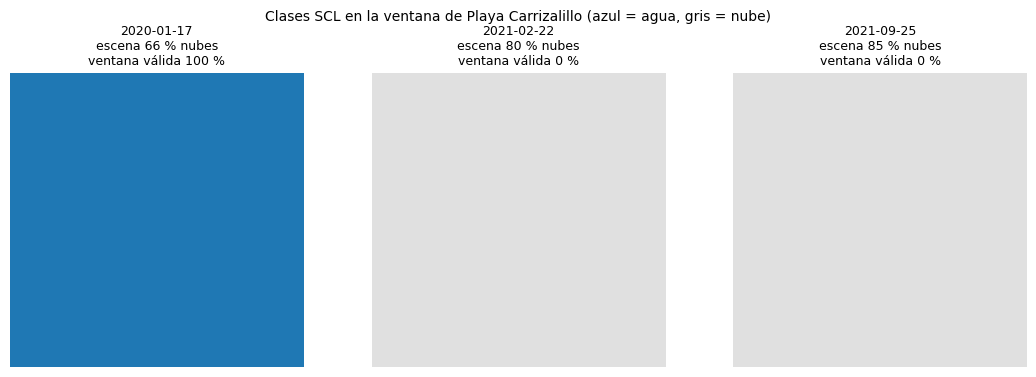

In [18]:
nombre_sitio = "Playa Carrizalillo"
ventana = ventanas["carrizalillo"]

excluir = [0, 1, 3, 8, 9, 10]
# sin datos, saturado, sombra de nube, nube media, nube alta y cirrus
valida = ~ventana["SCL"].isin(excluir)  # True donde el píxel es válido
fraccion_valida = valida.mean(["x", "y"]).to_series()
orden = fraccion_valida.sort_values(ascending=False)
elegidas = [orden.index[0], orden.index[len(orden) // 2], orden.index[-1]]

colores_scl = ["#000000", "#ff0000", "#4d4d4d", "#8b4513", "#33a02c", "#e6d28c",
               "#1f78b4", "#bdbdbd", "#9a9a9a", "#e0e0e0", "#a6cee3", "#ffffff"]
cmap_scl = ListedColormap(colores_scl)
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.8))
for eje, fecha in zip(ejes, elegidas):
    imagen = ventana["SCL"].sel(time=fecha).values
    eje.imshow(imagen, cmap=cmap_scl, vmin=-0.5, vmax=11.5)
    nubes_fecha = float(ventana["nubes_escena"].sel(time=fecha))
    eje.set_title(f"{pd.Timestamp(fecha):%Y-%m-%d}\nescena {nubes_fecha:.0f} % nubes\n"
                  f"ventana válida {100 * fraccion_valida[fecha]:.0f} %", fontsize=9)
    eje.axis("off")
plt.suptitle(f"Clases SCL en la ventana de {nombre_sitio} (azul = agua, gris = nube)", fontsize=10)
plt.tight_layout()
plt.show()

Se calculan los índices espectrales de la ventana de Carrizalillo. Primero se toman las bandas verde (B03), roja (B04), borde rojo (B05) e infrarrojo cercano (B08), y se enmascaran los píxeles no válidos según la SCL (nubes, sombras, cirros o sin datos), que quedan como NaN. Luego los valores digitales se convierten a reflectancia, aplicando el factor de escala y el offset de cada fecha. Con esa reflectancia se calculan tres índices: NDWI (agua, a partir del verde y el NIR), NDCI (clorofila, a partir del borde rojo y el rojo) y NDVI (vegetación, a partir del NIR y el rojo). También se guarda la reflectancia roja (B04) como indicador de turbidez. Al final se imprime la mediana de B04 en la fecha más despejada, para verificar que los valores estén en un rango razonable para agua.

In [19]:
espectrales = ventana[["B03", "B04", "B05", "B08"]]
enmascarada = espectrales.where(valida)  # píxeles con nube, sombra, cirrus o sin dato -> NaN
refl = reflectancia_sentinel2(enmascarada)  # DN * 0.0001 + offset de cada fecha
indices = xr.Dataset({
    "NDWI_AGUA": (refl["B03"] - refl["B08"]) / (refl["B03"] + refl["B08"]),  # verde y NIR
    "NDCI": (refl["B05"] - refl["B04"]) / (refl["B05"] + refl["B04"]),  # borde rojo y rojo
    "NDVI": (refl["B08"] - refl["B04"]) / (refl["B08"] + refl["B04"]),  # NIR y rojo
    "B04": refl["B04"],  # reflectancia roja
})
print("Variables:", list(indices.data_vars))
print(f"Reflectancia roja de la ventana, fecha más despejada: mediana {float(refl['B04'].sel(time=elegidas[0]).median()):.4f}")

Variables: ['NDWI_AGUA', 'NDCI', 'NDVI', 'B04']
Reflectancia roja de la ventana, fecha más despejada: mediana 0.0639


Una fecha, un número: la **mediana de la ventana** (los píxeles dentro de los 150 m del punto que no están enmascarados). Si menos de la mitad de la ventana quedó libre de nubes, la fecha se conserva pero su valor queda en NaN, para que el hueco se vea.

## 5. La serie de todos los puntos

`construir_series` hace estos mismos pasos para los seis puntos y entrega una **tabla ancha**: una fila por punto y fecha.

* `ndwi`, `ndci`, `b04` y `ndvi`: la mediana de la ventana.
* `nubes_escena`: las nubes de la escena completa (el filtro del catálogo).
* `pixeles_validos`: la fracción de la ventana que pasó la máscara SCL (lo que pasa en **tu** punto).
* `offset_reflectancia`: el offset aplicado a esa fecha.

In [20]:
serie = construir_series(ventanas, puntos, radio_m=RADIO_M, fraccion_minima=0.5)
print(f"{len(serie)} filas, {serie['fecha'].nunique()} fechas distintas")
serie.head(8)

5934 filas, 989 fechas distintas


,id,nombre,tipo,lat,lon,fecha,ndwi,ndci,b04,ndvi,nubes_escena,pixeles_validos,n_pixeles,offset_reflectancia
0,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-02 14:47:19.024,NaN,NaN,NaN,NaN,83.536118,0.0,704,0.0
1,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-04 14:37:21.024,NaN,NaN,NaN,NaN,64.026910,0.0,704,0.0
2,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-07 14:47:21.024,0.056287,0.013010,0.0623,0.001462,3.317222,1.0,704,0.0
3,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-09 14:37:19.024,0.552343,-0.036145,0.0050,-0.200000,0.854408,1.0,704,0.0
4,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-12 14:46:59.024,NaN,NaN,NaN,NaN,77.562638,0.0,704,0.0
5,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-14 14:37:01.024,NaN,NaN,NaN,NaN,73.744091,0.0,704,0.0
6,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-17 14:47:01.024,NaN,NaN,NaN,NaN,65.747337,0.0,704,0.0
7,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-19 14:36:59.024,NaN,NaN,NaN,NaN,62.871857,0.0,704,0.0


`resumen_validez` cuenta, por punto, las fechas con cobertura y las fechas que aportan un valor útil:

In [21]:
resumen_validez(serie)

,nombre,fechas,fechas_validas,porcentaje_valido,primera_valida,ultima_valida,nubes_escena_media,pixeles_validos_medio
id,,,,,,,,
callejon,Callejón Isla Choros y Damas,989,313,32.0,2020-01-07 14:47:21.024,2026-09-29 14:37:41.025,49.7,0.32
carrizalillo,Playa Carrizalillo,989,330,33.0,2020-01-07 14:47:21.024,2026-09-24 14:37:39.024,49.7,0.33
elapolillado,Playa El Apolillado,989,309,31.0,2020-01-07 14:47:21.024,2026-09-29 14:37:41.025,49.7,0.30
elapolillado02,El Apolillado 02,989,320,32.0,2020-01-07 14:47:21.024,2026-09-29 14:37:41.025,49.7,0.32
humedal_loschoros,Humedal Quebrada Los Choros,989,372,38.0,2020-01-09 14:37:19.024,2026-09-29 14:37:41.025,49.7,0.37
playa_loschoros,Playa Los Choros,989,360,36.0,2020-01-09 14:37:19.024,2026-09-27 14:47:29.024,49.7,0.37


## 6. Filtro de escena frente a máscara SCL: lo medimos

Con una sola carga (de hasta 100 % de nubes) podemos simular cuatro límites de nubes de escena, **con** y **sin** máscara SCL. Para "sin máscara" volvemos a llamar a `construir_series` con `excluir=[]` (no se descarta ninguna clase SCL; solo se quitan los píxeles sin dato).

Contamos las **fechas válidas** (con NDWI calculado) sumando los seis puntos.

In [22]:
sin_scl = construir_series(ventanas, puntos, radio_m=RADIO_M, fraccion_minima=0.5, excluir=[])

filas = []
for limite in (100, 60, 30, 10):
    for nombre, tabla in (("sin máscara SCL", sin_scl), ("con máscara SCL", serie)):
        sub = tabla[tabla["nubes_escena"] <= limite]
        filas.append({"límite de nubes de escena (%)": limite, "máscara": nombre,
                      "fechas": len(sub), "fechas válidas": int(sub["ndwi"].notna().sum())})
comparacion = pd.DataFrame(filas)
ancho = comparacion.pivot(index="límite de nubes de escena (%)", columns="máscara", values=["fechas", "fechas válidas"])
ancho = ancho.sort_index(ascending=False)
ancho

fechas                  fechas válidas  \
máscara                       con máscara SCL sin máscara SCL con máscara SCL   
límite de nubes de escena (%)                                                   
100                                      5934            5934            2004   
60                                       3257            3257            1885   
30                                       1819            1819            1499   
10                                       1044            1044             977   

                                               
máscara                       sin máscara SCL  
límite de nubes de escena (%)                  
100                                      5755  
60                                       3227  
30                                       1813  
10                                       1040

Lo importante está en la diferencia entre las dos columnas de *fechas válidas*. Sin máscara casi todas las fechas parecen válidas, **incluso las nubladas**: una nube es un píxel brillante con valores "razonables", no un dato faltante. La máscara SCL reconoce esas fechas y las deja en NaN.

¿Cuántas de las fechas "válidas sin máscara" tienen en realidad más de la mitad de su ventana tapada? Son las fechas **contaminadas**: si las dejaras, entrarían nubes a tu serie.

In [23]:
unidas = sin_scl.merge(serie, on=["id", "fecha"], suffixes=("_sin", "_con"))
unidas["contaminada"] = unidas["ndwi_sin"].notna() & unidas["ndwi_con"].isna()
filas = []
for limite in (100, 60, 30, 10):
    sub = unidas[unidas["nubes_escena_sin"] <= limite]
    filas.append({"límite de nubes de escena (%)": limite,
                  "fechas válidas sin máscara": int(sub["ndwi_sin"].notna().sum()),
                  "de ellas, contaminadas": int(sub["contaminada"].sum()),
                  "% de píxeles que quita la máscara": round(100 * (1 - sub["pixeles_validos_con"].mean()), 1)})
pd.DataFrame(filas).set_index("límite de nubes de escena (%)")

,fechas válidas sin máscara,"de ellas, contaminadas",% de píxeles que quita la máscara
límite de nubes de escena (%),,,
100,5755,3751,66.300003
60,3227,1342,42.299999
30,1813,314,17.799999
10,1040,63,6.700000


Así se ve la contaminación en el NDWI de los puntos de agua: las fechas contaminadas (sin máscara) se alejan de las válidas porque están midiendo nube.

Se comparan los valores de NDWI de los sitios marinos en dos grupos de fechas. Las válidas son las observaciones que sobreviven a la máscara de nubes de la SCL. Las contaminadas son las fechas que solo tienen dato cuando no se aplica la máscara, es decir, las que la máscara habría descartado. Se muestran como diagramas de caja con el número de observaciones de cada grupo. Si las distribuciones son claramente distintas, eso indica que las fechas contaminadas no reflejan el agua sino nubes o sombras, y que aplicar la máscara es necesario.

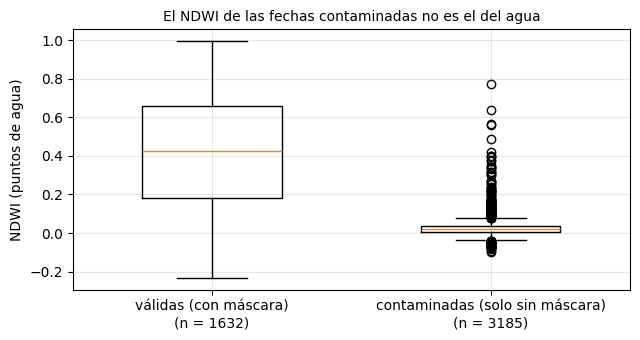

In [24]:
tipos_agua = ["bahia", "playa", "insular"]
agua = unidas[unidas["tipo_sin"].str.lower().isin(tipos_agua)]

grupos = {
    "válidas (con máscara)": agua.loc[agua["ndwi_con"].notna(), "ndwi_con"],
    "contaminadas (solo sin máscara)": agua.loc[agua["contaminada"], "ndwi_sin"],
}
fig, eje = plt.subplots(figsize=(6.5, 3.5))
eje.boxplot(list(grupos.values()),
            tick_labels=[f"{k}\n(n = {len(v)})" for k, v in grupos.items()], widths=0.5)
eje.set_ylabel("NDWI (puntos de agua)")
eje.set_title("El NDWI de las fechas contaminadas no es el del agua", fontsize=10)
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Los dos grupos de fechas tienen distribuciones de NDWI muy distintas:

Fechas válidas (con máscara): mediana cercana a 0.42 y la mitad central de los datos entre 0.18 y 0.66. Son valores positivos, típicos de agua.
Fechas contaminadas: se concentran en un rango muy estrecho alrededor de 0 (entre 0 y 0.04 aproximadamente). Eso es lo esperable para nubes, que reflejan casi lo mismo en el verde y en el infrarrojo cercano, así que el índice queda cerca de cero.

Esto confirma que las fechas que la máscara descarta no representan el agua. Si se incluyeran, bajarían artificialmente el NDWI de la serie. La amplitud del grupo válido, con algunos valores negativos y otros cercanos a 1, refleja tanto la variabilidad real del agua como posibles píxeles de borde costero o nubes residuales que la máscara no detectó.

## 7. Guardar la serie en parquet con metadatos (el momento FAIR)

Una tabla suelta en la memoria de Colab se pierde al cerrar la sesión y nadie sabe de dónde salió. En **parquet** la tabla conserva sus tipos y los **metadatos viajan dentro del mismo archivo**: título, descripción, fuente, licencia, parámetros y qué significa cada columna. Es el paso que vuelve tu serie *encontrable, accesible, interoperable y reutilizable*: este archivo es el que pasa a los bloques siguientes.

In [29]:
metadatos = {
    "titulo": f"Series temporales Sentinel-2 en puntos de agua y costa de Los Choros, Punta de Choros y Carrizalillo, Coquimbo ({FECHAS[0]} a {FECHAS[1]})",
    "descripcion": ("Mediana, en una ventana circular de 150 m de radio alrededor de cada punto, del NDWI de McFeeters (B03 y B08), "
                    "el NDCI (B05 y B04), la reflectancia roja B04 y el NDVI (B08 y B04) de Sentinel-2 L2A. Píxeles con nubes, "
                    "sombras, cirros, saturados o sin dato (SCL) descartados antes de resumir; las fechas con menos de la mitad "
                    "de la ventana válida tienen los índices en NaN. Incluye cinco puntos costeros e insulares y un humedal "
                    "(Quebrada Los Choros), cuyo píxel no corresponde a agua abierta."),
    "fuente": "ESA Copernicus Sentinel-2 L2A, leído como COG desde Microsoft Planetary Computer (colección sentinel-2-l2a)",
    "licencia": "Datos Copernicus Sentinel de acceso libre y abierto (Reglamento UE 1159/2013). Cita: contiene datos Copernicus Sentinel modificados (2026).",
    "periodo": f"{FECHAS[0]} a {FECHAS[1]}",
    "generado": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "parametros": {"nubes_max_escena": 100, "radio_m": RADIO_M, "estadistico": "mediana",
                   "fraccion_minima_pixeles_validos": 0.5, "resolucion_m": 10,
                   "crs": "UTM de los puntos (EPSG:32719)", "catalogo": "planetary"},
    "columnas": {
        "id": "identificador del punto", "nombre": "nombre del punto",
        "tipo": "tipo de sitio (humedal, insular, playa, bahia)",
        "lat": "latitud, grados (EPSG:4326)", "lon": "longitud, grados (EPSG:4326)",
        "fecha": "fecha y hora UTC de la toma",
        "ndwi": "(B03 - B08) / (B03 + B08), adimensional, positivo sobre agua",
        "ndci": "(B05 - B04) / (B05 + B04), adimensional, sube con la clorofila",
        "b04": "reflectancia roja (0 a 1), sube con la turbidez",
        "ndvi": "(B08 - B04) / (B08 + B04), adimensional",
        "nubes_escena": "% de nubes de la escena completa (eo:cloud_cover)",
        "pixeles_validos": "fracción (0 a 1) de la ventana que pasó la máscara SCL",
        "n_pixeles": "píxeles de la ventana",
        "offset_reflectancia": "offset aplicado a esa fecha (0 o -0.1), según baseline y catálogo"},
}
archivo = Path("serie_humboldt_sentinel2.parquet")  # en Colab queda en /content (panel de archivos de la izquierda)
guardar_series(serie, archivo, metadatos)
print(f"Guardado: {archivo} ({archivo.stat().st_size / 1024:.0f} kB)")

Guardado: serie_humboldt_sentinel2.parquet (102 kB)


Para comprobar que el archivo se entiende sin este cuaderno, léelo de vuelta junto con sus metadatos:

In [30]:
recuperada = pd.read_parquet(archivo)
# Los metadatos viajan dentro del archivo, como bytes (la clave "pandas" es de pandas y no nos interesa)
leidos = {k.decode(): v.decode() for k, v in pq.read_schema(archivo).metadata.items() if k != b"pandas"}
print(recuperada.dtypes.to_string())
print("\nMetadatos dentro del archivo:", ", ".join(leidos))
print("Título:", leidos["titulo"])

id                             object
nombre                         object
tipo                           object
lat                           float64
lon                           float64
fecha                  datetime64[ns]
ndwi                          float64
ndci                          float64
b04                           float64
ndvi                          float64
nubes_escena                  float64
pixeles_validos               float32
n_pixeles                       int64
offset_reflectancia           float64

Metadatos dentro del archivo: titulo, descripcion, fuente, licencia, periodo, generado, parametros, columnas
Título: Series temporales Sentinel-2 en puntos de agua y costa de Los Choros, Punta de Choros y Carrizalillo, Coquimbo (2020-01-01 a 2026-10-01)


## 8. La serie de 12 meses de respaldo y su gráfico

La carga en vivo de casi siete años de imágenes puede tardar bastante y, en Colab, fallar si se corta la conexión. Por eso existe también una serie ya preparada con el mismo flujo, series_sentinel2_humboldt.parquet, que cubre los seis puntos de Los Choros, Punta de Choros y Carrizalillo entre 2020 y 2026. Es la que se usó en el notebook de exploración y sirve como respaldo si la carga en vivo falla.

Antes de usarla, se hace una prueba de reproducibilidad. Las fechas que ambas series tienen en común, aplicando el mismo filtro de nubosidad de escena, deberían tener exactamente los mismos valores.

In [31]:
respaldo = pd.read_parquet(DATOS / "serie_humboldt_sentinel2.parquet")
print(f"Respaldo: {len(respaldo)} filas, {respaldo['fecha'].min():%Y-%m-%d} a {respaldo['fecha'].max():%Y-%m-%d}")

nubes_max_respaldo = 60  # filtro de escena con que se preparó el respaldo
variables = ["ndwi", "ndci", "b04", "ndvi", "pixeles_validos"]

nuestra = serie[serie["nubes_escena"] <= nubes_max_respaldo].set_index(["id", "fecha"]).sort_index()
suya = (respaldo[(respaldo["fecha"] >= FECHAS[0]) & (respaldo["fecha"] <= f"{FECHAS[1]} 23:59")]
        .set_index(["id", "fecha"]).sort_index())
comunes = nuestra.index.intersection(suya.index)
diferencia = (nuestra.loc[comunes, variables] - suya.loc[comunes, variables]).abs().max()
print(f"Filas en común: {len(comunes)} (nuestra: {len(nuestra)}, respaldo: {len(suya)})")
print("Diferencia máxima por variable:", diferencia.round(6).to_dict())

Respaldo: 5934 filas, 2020-01-02 a 2026-09-29
Filas en común: 3257 (nuestra: 3257, respaldo: 5934)
Diferencia máxima por variable: {'ndwi': 0.0, 'ndci': 0.0, 'b04': 0.0, 'ndvi': 0.0, 'pixeles_validos': 0.0}


Resultado: las 3257 observaciones de la serie generada en vivo (con hasta 60 % de nubes de escena) aparecen también en el respaldo, y la diferencia máxima entre ambas es exactamente 0 en todas las variables. El flujo es completamente reproducible: al volver a descargar y procesar las mismas imágenes con los mismos parámetros, se obtienen los mismos valores. El respaldo tiene más filas (5934) porque incluye también las escenas con más de 60 % de nubes, que aquí se filtraron antes de comparar.

Se grafican las series completas de Sentinel-2 de los seis puntos en un gráfico interactivo con cuatro paneles, uno por variable: NDWI (agua), NDCI (clorofila), B04 (turbidez) y NDVI (vegetación). Cada sitio tiene su propio color y cada panel su propia escala. Las fechas sin dato válido se omiten en vez de rellenarse. Al ser interactivo, se puede hacer zoom en un periodo, pasar el cursor sobre un punto para ver su valor y fecha, u ocultar sitios desde la leyenda para compararlos mejor.

In [32]:
etiquetas = {"ndwi": "NDWI (agua)", "ndci": "NDCI (clorofila)",
             "b04": "B04, reflectancia roja (turbidez)", "ndvi": "NDVI (vegetación)"}

# plotly pide una fila por observación y variable ("formato largo"); las fechas sin valor (NaN) se omiten
largo = respaldo.melt(id_vars=["nombre", "fecha"], value_vars=list(etiquetas),
                      var_name="variable", value_name="valor")
largo["variable"] = largo["variable"].map(etiquetas)
largo = largo.dropna(subset=["valor"])

inicio, fin = respaldo["fecha"].min(), respaldo["fecha"].max()
fig = px.line(largo, x="fecha", y="valor", color="nombre", facet_row="variable", markers=True,
              category_orders={"variable": list(etiquetas.values())}, color_discrete_sequence=PALETA,
              title=f"Series Sentinel-2 por punto, Los Choros y Carrizalillo ({inicio:%Y-%m} a {fin:%Y-%m})",
              height=900, labels={"fecha": "Fecha", "valor": "", "nombre": "Punto"})
fig.update_yaxes(matches=None)  # cada panel con su propia escala
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))  # "variable=NDWI" -> "NDWI"
fig.show()

Cómo mirarlo.

El humedal de Quebrada Los Choros se separa claramente de los puntos de agua en las cuatro variables:

NDWI: siempre negativo, entre −0.1 y −0.25.
NDVI: levemente positivo, entre 0.05 y 0.15, con pequeños aumentos en invierno.
B04: la más alta de todos los sitios, alrededor de 0.2.

Es la firma de un píxel de suelo con vegetación escasa, no de agua. Su NDVI no es alto en términos absolutos, pero sí es el único positivo.

En los cinco puntos de agua, el NDWI es positivo y el NDVI negativo, como se espera sobre agua. Las series son muy ruidosas: el NDWI oscila entre 0 y 1 de una fecha a otra, y el NDCI tiene caídas bruscas. Entre ellos, Playa El Apolillado tiene la reflectancia roja más alta, lo que podría indicar más turbidez o influencia de la costa en su ventana. Los picos aislados de B04 sobre 0.5 se repiten en varios sitios en las mismas fechas, por lo que probablemente son nubes o reflejo solar no detectados por la máscara, y no eventos reales de turbidez.

Por ese ruido, conviene leer estas series con medianas mensuales o medias móviles más que fecha a fecha.

## Cierre

* Una serie por punto se construye cargando **ventanas pequeñas**, no la caja completa.
* El offset de reflectancia se decide **por fecha** (`agregar_offset`); nunca se fija a mano.
* Filtro de escena y máscara SCL no son lo mismo: la máscara es la que protege tu punto. Úsalas juntas.
* El parquet con metadatos es el momento FAIR: el archivo se explica solo y pasa al bloque 5.

Entregable del día: este cuaderno con tu serie guardada en parquet.

In [33]:
# Limpieza: borra el parquet de práctica si no lo necesitas (en Colab desaparece al cerrar la sesión)
# archivo.unlink()